## CNN para classificação do dataset Food-101 (Keras)

- tamanhos variáveis, 3 canais (RGB)
- classes: 101 tipos de comida

In [1]:
import numpy as np
import keras
from keras import layers
import tensorflow as tf
import kagglehub # baixar datasets

import numpy as np
import matplotlib.pyplot as plt
import random
import shutil
import os

In [2]:
dataset_path = kagglehub.dataset_download("dansbecker/food-101")
print("Dataset baixado em:", dataset_path)

Dataset baixado em: /Users/juliacohen/.cache/kagglehub/datasets/dansbecker/food-101/versions/1


In [3]:
images_dir = os.path.join(dataset_path, "food-101", "food-101", "images")
print("Classes encontradas:", len(os.listdir(images_dir)))
print("Exemplos de classes:", os.listdir(images_dir)[:5])
# apagar a classe extra
ds_store_path = os.path.join(images_dir, ".Ds_Store")
if os.path.exists(ds_store_path):
    os.remove(ds_store_path)
    print("Removido: ", ds_store_path)
else: 
    print("Não encontrado, ja foi removido")

classes = os.listdir(images_dir)
print("Classes encontradas:", len(classes))

Classes encontradas: 101
Exemplos de classes: ['foie_gras', 'club_sandwich', 'cheese_plate', 'cup_cakes', 'garlic_bread']
Não encontrado, ja foi removido
Classes encontradas: 101


In [12]:
IMG_SIZE = (128, 128) #imagens redimensionadas para 128x128
BATCH_SIZE = 32 # imagens processadas por vez
NUM_CLASSES = 101
MAX_IMAGES_PER_CLASS = None
EPOCHS = 50 # no treino
VALIDATION_SPLIT = 0.2 # 20% do dataset para validacao

SELECTED_CLASSES = None

In [5]:
def build_subset_dir(source_dir, target_dir, max_per_class):
    # Cria uma pasta com no máximo max_per_class imagens por classe
    if os.path.exists(target_dir):
        shutil.rmtree(target_dir)
    os.makedirs(target_dir, exist_ok=True)

    # Se foram passadas classes específicas, usa só elas; senão, usa todas
    if SELECTED_CLASSES is not None:
        classes = SELECTED_CLASSES
    else:
        classes = sorted(os.listdir(source_dir))

    for cls in classes:
        src_cls_dir = os.path.join(source_dir, cls)
        dst_cls_dir = os.path.join(target_dir, cls)
        os.makedirs(dst_cls_dir, exist_ok=True)

        files = os.listdir(src_cls_dir)
        random.shuffle(files)
        if max_per_class is not None:
            files = files[:max_per_class]

        for f in files:
            src_file = os.path.join(src_cls_dir, f)
            dst_file = os.path.join(dst_cls_dir, f)
            if not os.path.exists(dst_file):
                os.symlink(src_file, dst_file)
    return target_dir


subset_dir = os.path.join(os.getcwd(), "food101_subset")
data_dir = build_subset_dir(images_dir, subset_dir, MAX_IMAGES_PER_CLASS)
print("Subconjunto criado em:", data_dir)
print("Classes usadas:", os.listdir(data_dir))

Subconjunto criado em: /Users/juliacohen/Documents/UEA-LOCAL/wheidima/cnn-food-101/food101_subset
Classes usadas: ['foie_gras', 'club_sandwich', 'cheese_plate', 'cup_cakes', 'garlic_bread', 'gnocchi', 'ice_cream', 'samosa', 'donuts', 'tuna_tartare', 'filet_mignon', 'seaweed_salad', 'french_toast', 'chicken_curry', 'shrimp_and_grits', 'steak', 'cheesecake', 'red_velvet_cake', 'waffles', 'churros', 'gyoza', 'lobster_roll_sandwich', 'huevos_rancheros', 'breakfast_burrito', 'grilled_cheese_sandwich', 'spaghetti_bolognese', 'falafel', 'poutine', 'greek_salad', 'beef_tartare', 'fried_calamari', 'guacamole', 'ravioli', 'lobster_bisque', 'beet_salad', 'risotto', 'crab_cakes', 'strawberry_shortcake', 'edamame', 'ceviche', 'hot_and_sour_soup', 'spring_rolls', 'sashimi', 'paella', 'clam_chowder', 'miso_soup', 'escargots', 'hot_dog', 'pulled_pork_sandwich', 'bruschetta', 'panna_cotta', 'fish_and_chips', 'pad_thai', 'tiramisu', 'takoyaki', 'macarons', 'apple_pie', 'cannoli', 'scallops', 'frozen_yog

In [6]:
# carrega o conjunto de treino 80%
train_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=VALIDATION_SPLIT,
    subset="training",
    seed=42, # garante que treino/validação sejam sempre divididos da mesma forma
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical" # rótulos em one-hot
)

# Carrega o conjunto de validacao
val_ds = keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=VALIDATION_SPLIT,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

class_names = train_ds.class_names
print("Número de classes carregadas:", len(class_names))

Found 101000 files belonging to 101 classes.
Using 80800 files for training.
Found 101000 files belonging to 101 classes.
Using 20200 files for validation.
Número de classes carregadas: 101


In [7]:
# aumentar dados com espelhar, girar, dar zoom para evitar overfitting
data_augmentation = keras.Sequential([layers.RandomFlip("horizontal"), 
                                 layers.RandomRotation(0.1), 
                                 layers.RandomZoom(0.1),
                                ])
# extra!
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(buffer_size=1000).cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [23]:
input_shape = IMG_SIZE + (3,) # (128, 128, 3)

model = keras.Sequential([
    keras.Input(shape=input_shape),
    data_augmentation, layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dropout(0.3), # evita que a rede decore o treino pq desliga aleatoriamente 50% dos neurônios a cada passo
    layers.Dense(256, activation="relu"), # camada densa extra: problema mais complexo, mais capacidade de decisão
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax"),  # a classe com maior probabilidade é a previsão final do modelo
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 101)            │        25,957 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,446,693 (5.52 MB)

 Trainable params: 1,446,693 (5.52 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
# model.compile(
#     optimizer="adam",
#     # Adaptive Moment Estimation
#     loss="categorical_crossentropy", # mais de uma classe
#     metrics=["accuracy"]
# )

lr_schedule = keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=0.001,
    decay_steps=10 * len(train_ds),  # 10 epochs * número de lotes por epoch
    decay_rate=0.5,
    staircase=True  # reduz em "degraus" a cada decay_steps, não continuamente
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_schedule),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

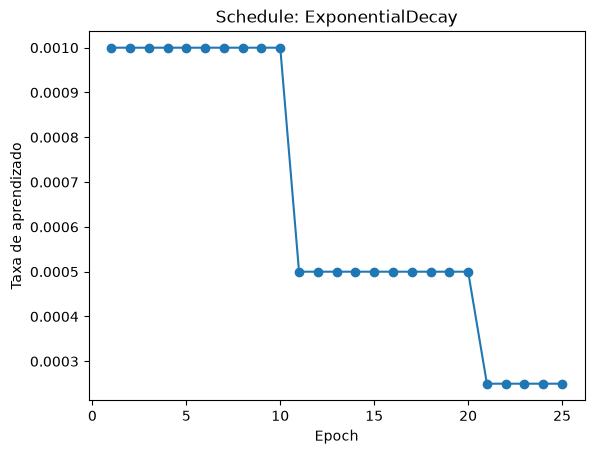

In [25]:
import matplotlib.pyplot as plt

steps = range(0, 25 * len(train_ds), len(train_ds))  # um ponto por epoch, 25 epochs
lrs = [lr_schedule(s).numpy() for s in steps]

plt.plot(range(1, 26), lrs, marker='o')
plt.xlabel("Epoch")
plt.ylabel("Taxa de aprendizado")
plt.title("Schedule: ExponentialDecay")
plt.show()

In [26]:
# Para de treinar automaticamente se a acurácia de validação não
# melhorar por 3 epochs seguidas, e restaura os melhores pesos encontrados
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_accuracy",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    shuffle=False
)

Epoch 1/50
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 287s 113ms/step - accuracy: 0.0488 - loss: 4.3119 - val_accuracy: 0.0983 - val_loss: 3.9813
Epoch 2/50
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 2150s 852ms/step - accuracy: 0.1042 - loss: 3.9194 - val_accuracy: 0.1293 - val_loss: 3.7814
Epoch 3/50
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 1585s 628ms/step - accuracy: 0.1414 - loss: 3.6905 - val_accuracy: 0.1621 - val_loss: 3.5720
Epoch 4/50
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 2487s 985ms/step - accuracy: 0.1708 - loss: 3.5371 - val_accuracy: 0.1954 - val_loss: 3.3997
Epoch 5/50
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 2179s 863ms/step - accuracy: 0.1851 - loss: 3.4370 - val_accuracy: 0.2080 - val_loss: 3.3492
Epoch 6/50
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 2482s 983ms/step - accuracy: 0.2018 - loss: 3.3556 - val_accuracy: 0.2198 - val_loss: 3.2832
Epoch 7/50
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 1506s 597ms/step - accuracy: 0.2135 - loss: 3.2979 - val_accuracy: 0.2314 - val_loss: 3.2219
Epoch 8/50
2525/2525 ━━━━━━━━━━━━━━━━━━━━ 308s 122ms/ste

In [27]:
print(model.output_shape)

(None, 101)


In [28]:
loss, accuracy = model.evaluate(val_ds, verbose=0)
print(f"Perda (loss) na validação: {loss:.4f}")
print(f"Acurácia na validação: {accuracy:.4f}")

Perda (loss) na validação: 2.6234
Acurácia na validação: 0.3602


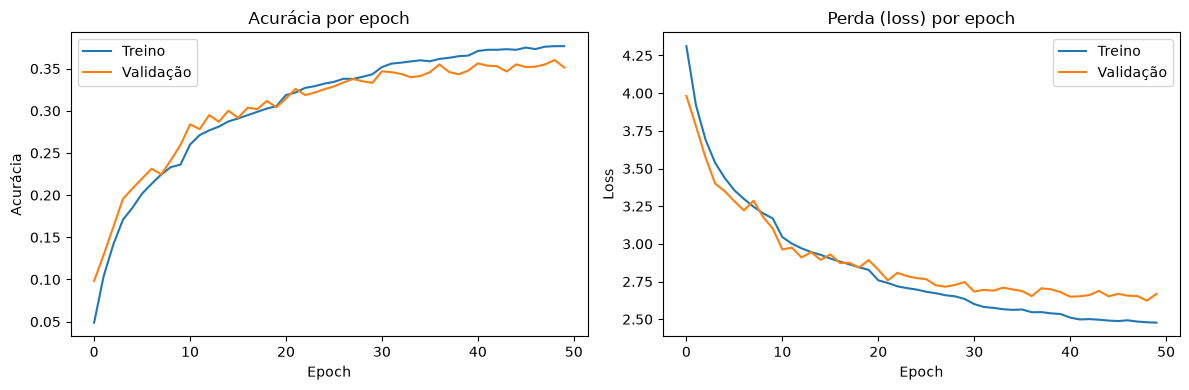

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico de acurácia
axes[0].plot(history.history["accuracy"], label="Treino")
axes[0].plot(history.history["val_accuracy"], label="Validação")
axes[0].set_title("Acurácia por epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Acurácia")
axes[0].legend()

# Gráfico de perda
axes[1].plot(history.history["loss"], label="Treino")
axes[1].plot(history.history["val_loss"], label="Validação")
axes[1].set_title("Perda (loss) por epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


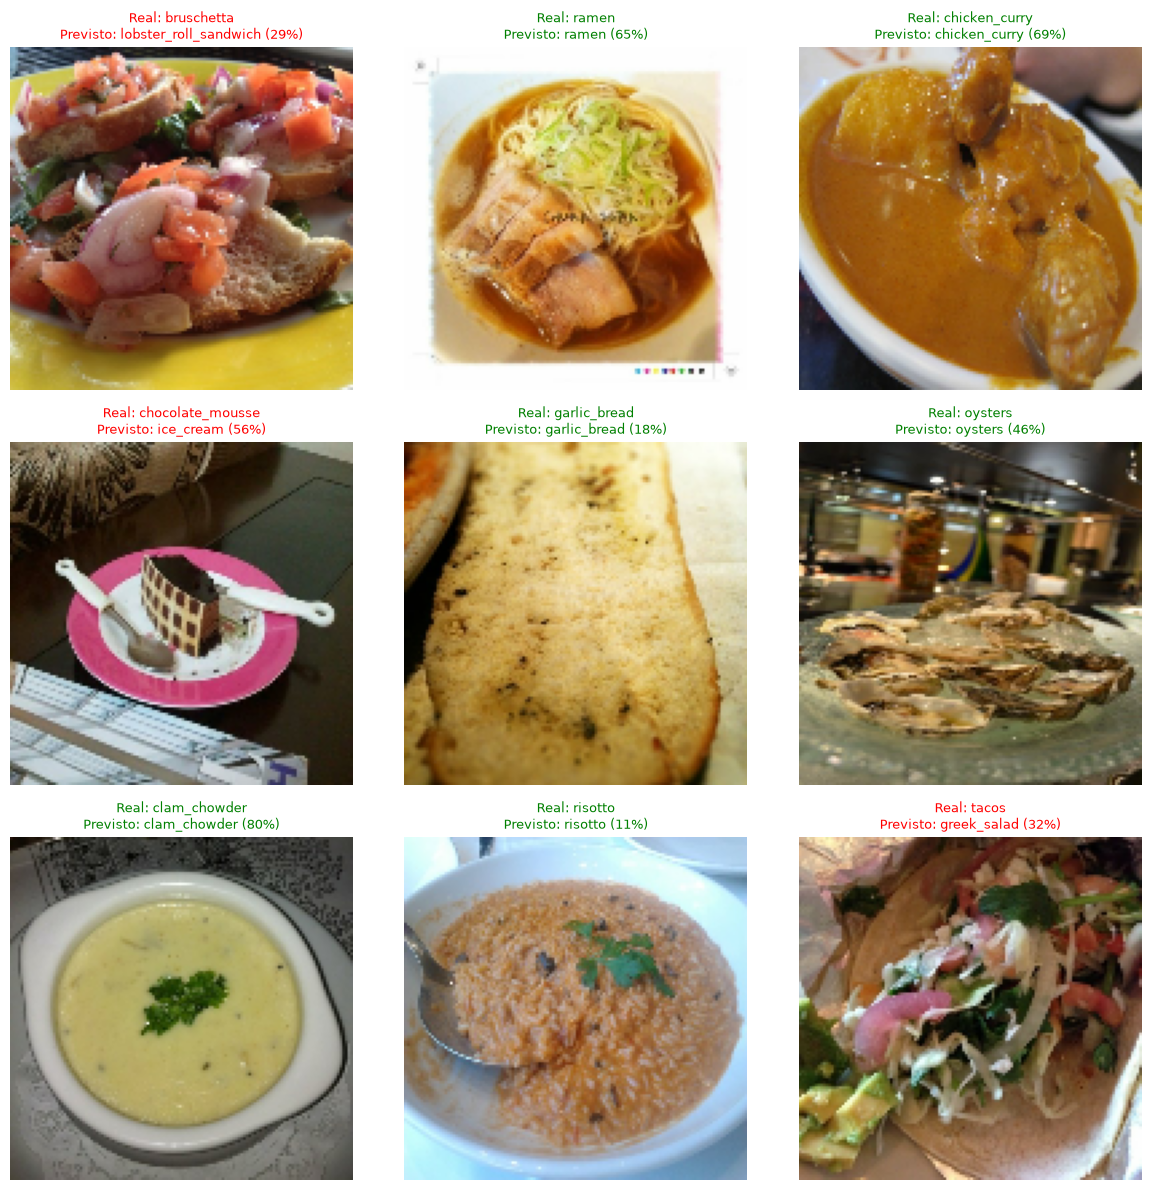

In [30]:
# Pega um lote de imagens do conjunto de validação
images, labels = next(iter(val_ds))
predictions = model.predict(images)

plt.figure(figsize=(12, 12))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))

    true_class = class_names[np.argmax(labels[i])]
    pred_class = class_names[np.argmax(predictions[i])]
    confidence = 100 * np.max(predictions[i])

    color = "green" if true_class == pred_class else "red"
    plt.title(f"Real: {true_class}\nPrevisto: {pred_class} ({confidence:.0f}%)",
              color=color, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()